# 1: Dataset Understanding
التعرف على البيانات وطبيعتها

In [28]:
# قراءة البيانات
import pandas as pd

# قراءة ملف البيانات 
df = pd.read_csv('/kaggle/input/datasets/fedesoriano/heart-failure-prediction/heart.csv')


In [29]:
# عرض أول 5 أسطر من الجدول لأخذ نظرة عامة على البيانات
print("أول 5 أسطر من البيانات ")
print(df.head())

أول 5 أسطر من البيانات 
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  


###  Dataset Overview & Description

This project utilizes the **Heart Failure Prediction Dataset** to predict the likelihood of heart disease based on clinical indicators. 

####  Dataset Dimensions:
* **Rows (Observations):** 918 patient records.
* **Columns (Variables):** 12 columns total (11 independent features + 1 dependent target variable).

####  Variables Definition:

* **Target Variable (Dependent):**
  * `HeartDisease`: Output class [1: Heart Disease, 0: Normal].

* **Numerical Features (Continuous):**
  * `Age`: Patient age (years).
  * `RestingBP`: Resting blood pressure (mm Hg).
  * `Cholesterol`: Serum cholesterol (mm/dl).
  * `MaxHR`: Maximum heart rate achieved.
  * `Oldpeak`: Numeric value of ST depression.

* **Categorical Features:**
  * `Sex`: Patient gender [M: Male, F: Female].
  * `ChestPainType`: [TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic].
  * `FastingBS`: Fasting blood sugar [1: if > 120 mg/dl, 0: otherwise].
  * `RestingECG`: Resting electrocardiogram [Normal, ST, LVH].
  * `ExerciseAngina`: Exercise-induced angina [Y: Yes, N: No].
  * `ST_Slope`: Slope of the peak exercise ST segment [Up, Flat, Down].

In [30]:
#  معرفة أبعاد وحجم البيانات (عدد الصفوف والأعمدة)
print(" حجم البيانات (Columns  ,  Rows) ")
print(df.shape)


 حجم البيانات (Columns  ,  Rows) 
(918, 12)


* جميع الاعمدة تحتوي على قيم مما يعني عدم وجود اي missing values
* انواع البيانات يوجد رقمية وعددها (7) و النصية عددها (5)


In [31]:
#  عرض معلومات شاملة (أسماء الأعمدة، أنواع البيانات، وهل توجد قيم مفقودة مبدئياً)
print(" معلومات عن الأعمدة وأنواع البيانات ")
print(df.info())

 معلومات عن الأعمدة وأنواع البيانات 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB
None


In [32]:
# استخراج الإحصائيات الوصفية للأعمدة الرقمية (المتوسط، أعلى وأقل قيمة)
print(" الإحصائيات الوصفية للبيانات ")
print(df.describe())

 الإحصائيات الوصفية للبيانات 
              Age   RestingBP  Cholesterol   FastingBS       MaxHR  \
count  918.000000  918.000000   918.000000  918.000000  918.000000   
mean    53.510893  132.396514   198.799564    0.233115  136.809368   
std      9.432617   18.514154   109.384145    0.423046   25.460334   
min     28.000000    0.000000     0.000000    0.000000   60.000000   
25%     47.000000  120.000000   173.250000    0.000000  120.000000   
50%     54.000000  130.000000   223.000000    0.000000  138.000000   
75%     60.000000  140.000000   267.000000    0.000000  156.000000   
max     77.000000  200.000000   603.000000    1.000000  202.000000   

          Oldpeak  HeartDisease  
count  918.000000    918.000000  
mean     0.887364      0.553377  
std      1.066570      0.497414  
min     -2.600000      0.000000  
25%      0.000000      0.000000  
50%      0.600000      1.000000  
75%      1.500000      1.000000  
max      6.200000      1.000000  


# 3: Data Preprocessing
# تجهيز البيانات قبل بناء نماذج تعلم الآلة

#### 1. Dependent Variable (Target Criterion)
* **`HeartDisease`**: The primary binary outcome variable designated for model classification and prediction. 
  * **[1]**: Indicates the clinical presence of heart disease (Positive Diagnostic Status).
  * **[0]**: Indicates a normal physiological condition (Negative Diagnostic Status).

#### 2. Independent Variables (Predictor Attributes)

##### A. Continuous Physiological Parameters:
* **`Age`**
* **`RestingBP`**
* **`Cholesterol`**
* **`MaxHR`**
* **`Oldpeak`**

##### B. Categorical and Diagnostic Attributes:
* **`Sex`**
* **`ChestPainType`**
* **`FastingBS`**
* **`RestingECG`**
* **`ExerciseAngina`**
* **`ST_Slope`**

In [33]:
# 1. Check for Duplicate Rows
# التأكد من عدم وجود بيانات مكررة
print("عدد الصفوف المكررة:")
print(df.duplicated().sum())

عدد الصفوف المكررة:
0


In [34]:
# 2. Convert Categorical Data to Numerical
# تحويل الأعمدة النصية إلى رقمية
from sklearn.preprocessing import LabelEncoder

encoder = LabelEncoder()

categorical_columns = [
    'Sex',
    'ChestPainType',
    'RestingECG',
    'ExerciseAngina',
    'ST_Slope'
]

for col in categorical_columns:
    df[col] = encoder.fit_transform(df[col])

print("تم تحويل البيانات النصية إلى رقمية")
print(df.head())

تم تحويل البيانات النصية إلى رقمية
   Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
0   40    1              1        140          289          0           1   
1   49    0              2        160          180          0           1   
2   37    1              1        130          283          0           2   
3   48    0              0        138          214          0           1   
4   54    1              2        150          195          0           1   

   MaxHR  ExerciseAngina  Oldpeak  ST_Slope  HeartDisease  
0    172               0      0.0         2             0  
1    156               0      1.0         1             1  
2     98               0      0.0         2             0  
3    108               1      1.5         1             1  
4    122               0      0.0         2             0  


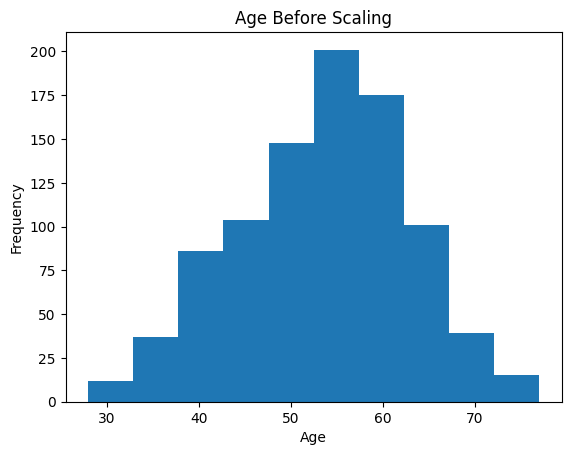

In [35]:
# 3. Visualization Before Scaling
# رسم توزيع الأعمار قبل المعالجة
import matplotlib.pyplot as plt

plt.hist(df['Age'])

plt.title('Age Before Scaling')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

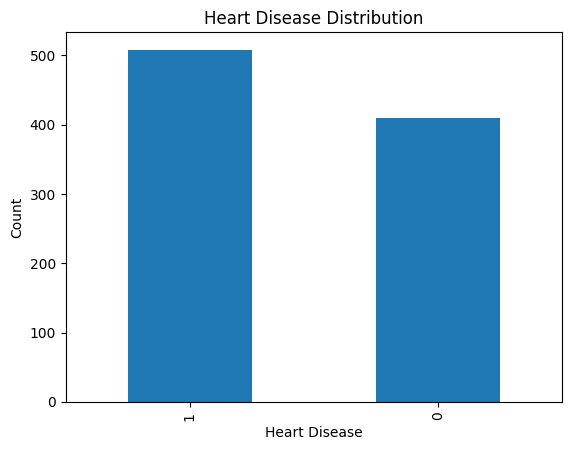

In [36]:
# 4. Heart Disease Distribution
# توزيع حالات مرض القلب
df['HeartDisease'].value_counts().plot(kind='bar')

plt.title('Heart Disease Distribution')
plt.xlabel('Heart Disease')
plt.ylabel('Count')

plt.show()

In [37]:
# 5. Define Features and Target
# تحديد بيانات الإدخال والهدف
X = df.drop('HeartDisease', axis=1)
y = df['HeartDisease']

print("تم تحديد بيانات الإدخال والهدف")

تم تحديد بيانات الإدخال والهدف


In [38]:
# 6. Split Data into Training and Testing
# تقسيم البيانات إلى تدريب واختبار
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("تم تقسيم البيانات")

تم تقسيم البيانات


In [39]:
# 7. Feature Scaling
# عمل Scaling للبيانات
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("تم عمل Scaling للبيانات")

تم عمل Scaling للبيانات


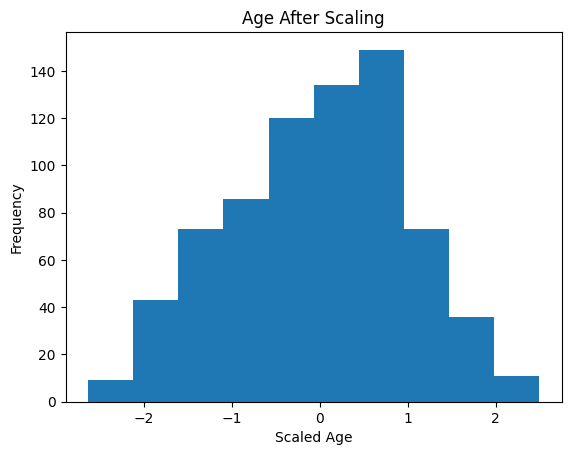

In [40]:
# 8. Visualization After Scaling
# رسم توزيع الأعمار بعد المعالجة
import pandas as pd

X_train_scaled = pd.DataFrame(X_train, columns=X.columns)

plt.hist(X_train_scaled['Age'])

plt.title('Age After Scaling')
plt.xlabel('Scaled Age')
plt.ylabel('Frequency')

plt.show()

# 4: Apply at least two machine learning models

In [41]:
# تحديد البيانات والمدخلات

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

In [42]:
# تقسيم البيانات

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# إنشاء مودل Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# تدريب المودل على بيانات التدريب
dt_model.fit(X_train, y_train)

# التنبؤ باستخدام بيانات الاختبار
dt_pred = dt_model.predict(X_test)

# حساب الدقة
dt_accuracy = accuracy_score(y_test, dt_pred)

# طباعة النتيجة
print("Decision Tree:", dt_accuracy)

# شرح النتيجة
print("\nشرح النتيجة :")
print("تم تدريب مودل Decision Tree باستخدام بيانات التدريب.")
print("بعد ذلك تم اختبار المودل على بيانات الاختبار.")
print("تمثل قيمة الدقة نسبة التوقعات الصحيحة التي قام بها المودل.")
print("كلما اقتربت القيمة من 1 فهذا يدل على أن أداء المودل أفضل.")

Decision Tree: 0.782608695652174

شرح النتيجة :
تم تدريب مودل Decision Tree باستخدام بيانات التدريب.
بعد ذلك تم اختبار المودل على بيانات الاختبار.
تمثل قيمة الدقة نسبة التوقعات الصحيحة التي قام بها المودل.
كلما اقتربت القيمة من 1 فهذا يدل على أن أداء المودل أفضل.


In [44]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# إنشاء مودل Logistic Regression
lr_model = LogisticRegression(max_iter=1000)

# تدريب المودل
lr_model.fit(X_train, y_train)

# التنبؤ باستخدام بيانات الاختبار
lr_pred = lr_model.predict(X_test)

# حساب الدقة
lr_accuracy = accuracy_score(y_test, lr_pred)

# طباعة النتيجة
print("Logistic Regression:", lr_accuracy)

# شرح النتيجة
print("\nشرح النتيجة :")
print("تم تدريب مودل Logistic Regression باستخدام البيانات.")
print("تم استخدام بيانات الاختبار لمعرفة مدى قدرة المودل على التنبؤ.")
print("تمثل قيمة الدقة نسبة التوقعات الصحيحة للمودل.")
print("القيمة الأعلى تعني أداء أفضل في التنبؤ بمرض القلب.")

Logistic Regression: 0.842391304347826

شرح النتيجة :
تم تدريب مودل Logistic Regression باستخدام البيانات.
تم استخدام بيانات الاختبار لمعرفة مدى قدرة المودل على التنبؤ.
تمثل قيمة الدقة نسبة التوقعات الصحيحة للمودل.
القيمة الأعلى تعني أداء أفضل في التنبؤ بمرض القلب.


Decision Tree Accuracy: 0.782608695652174


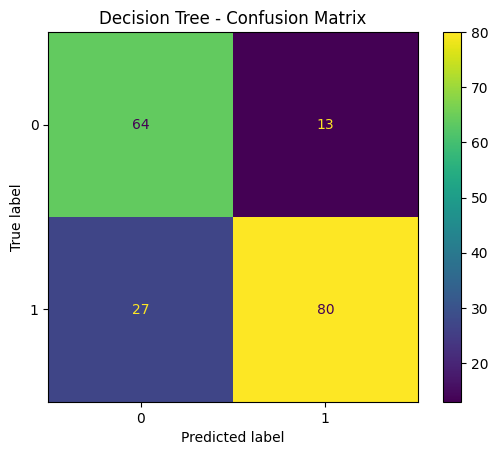

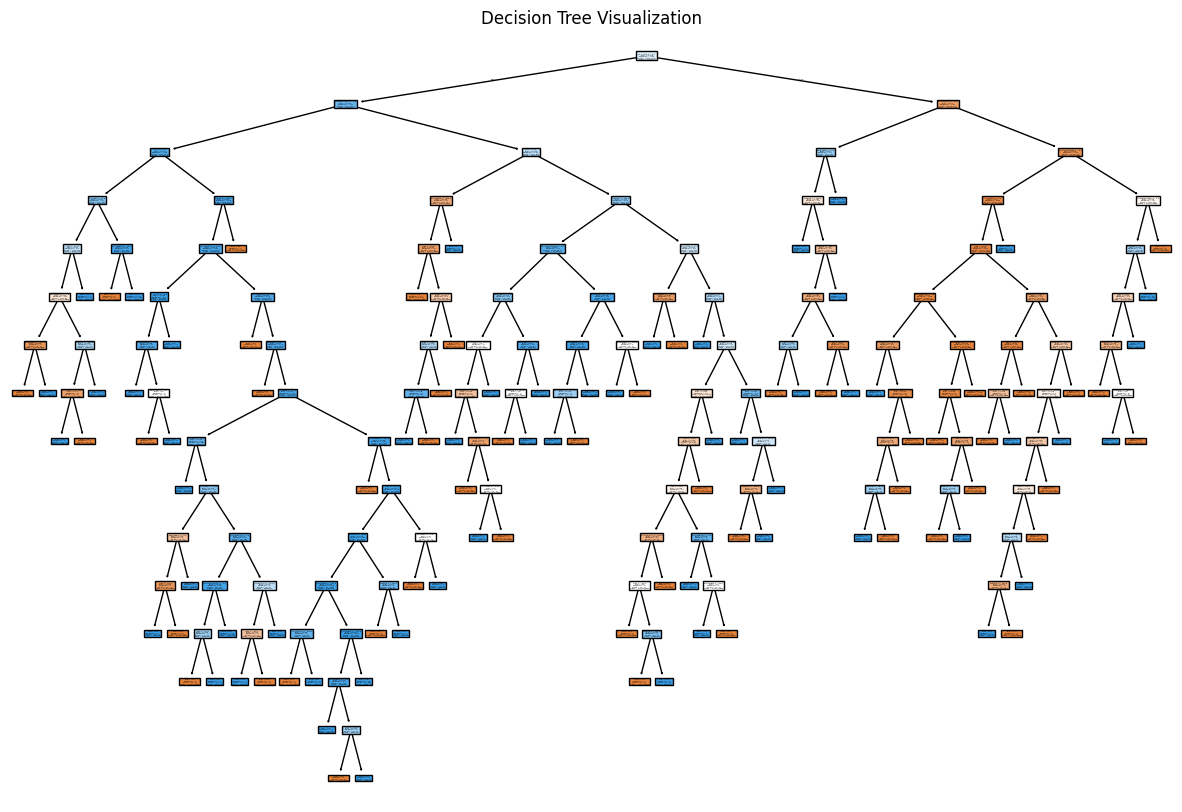

In [45]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# إنشاء مودل Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)

# تدريب المودل
dt_model.fit(X_train, y_train)

# التنبؤ
dt_pred = dt_model.predict(X_test)

# حساب الدقة
dt_accuracy = accuracy_score(y_test, dt_pred)

print("Decision Tree Accuracy:", dt_accuracy)

# =========================
# الرسم الأول: Confusion Matrix
# =========================

cm = confusion_matrix(y_test, dt_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Decision Tree - Confusion Matrix")
plt.show()

# =========================
# الرسم الثاني: رسم الشجرة
# =========================

plt.figure(figsize=(15,10))

plot_tree(
    dt_model,
    filled=True,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"]
)

plt.title("Decision Tree Visualization")

plt.show()

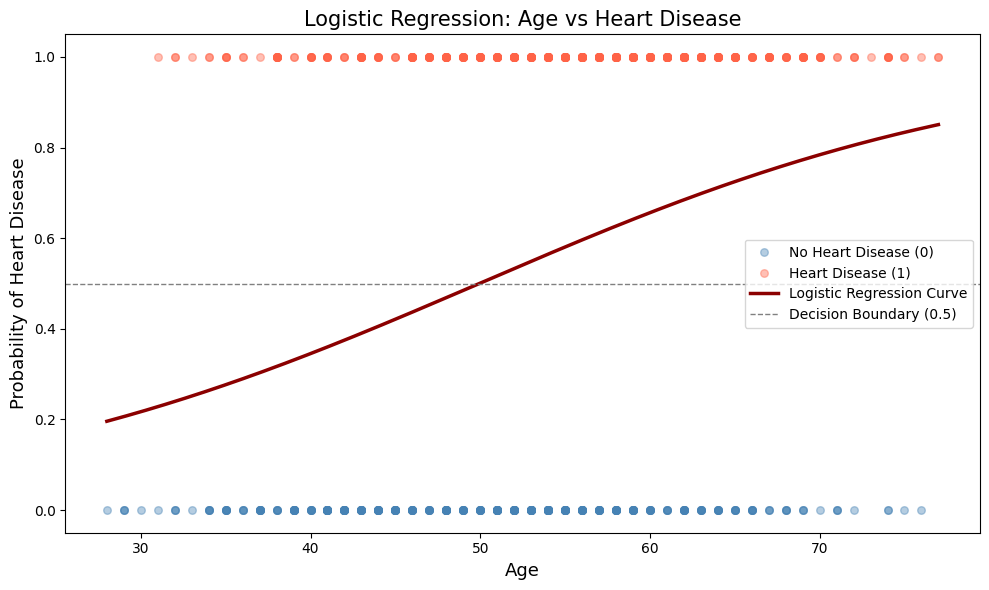

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression

# اختيار المتغير ورسم Logistic Regression

feature = 'Age'
X = df[[feature]].values
y = df['HeartDisease'].values

# تدريب النموذج
model = LogisticRegression()
model.fit(X, y)

# توليد النقاط للمنحنى
X_range = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)
y_prob = model.predict_proba(X_range)[:, 1]

# الرسم
plt.figure(figsize=(10, 6))
plt.scatter(df[df['HeartDisease'] == 0][feature], df[df['HeartDisease'] == 0]['HeartDisease'], 
            color='steelblue', alpha=0.4, label='No Heart Disease (0)', s=30)
plt.scatter(df[df['HeartDisease'] == 1][feature], df[df['HeartDisease'] == 1]['HeartDisease'], 
            color='tomato', alpha=0.4, label='Heart Disease (1)', s=30)
plt.plot(X_range, y_prob, color='darkred', linewidth=2.5, label='Logistic Regression Curve')
plt.axhline(y=0.5, color='gray', linestyle='--', linewidth=1, label='Decision Boundary (0.5)')
plt.xlabel(feature, fontsize=13)
plt.ylabel('Probability of Heart Disease', fontsize=13)
plt.title(f'Logistic Regression: {feature} vs Heart Disease', fontsize=15)
plt.legend()
plt.tight_layout()
plt.show()

# 5: Evaluate and compare models

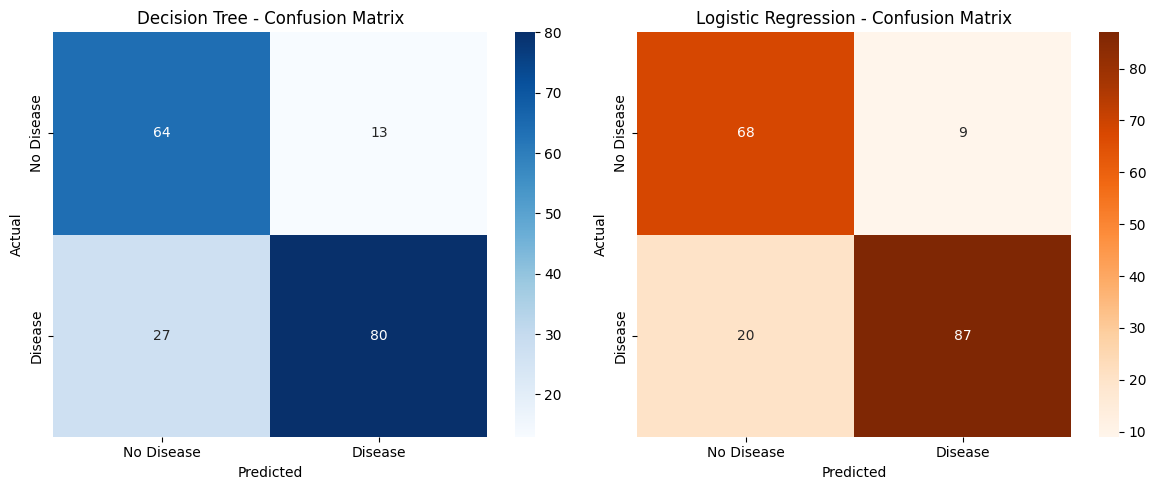

In [50]:
#task 5
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ===== Confusion Matrix for both models =====
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Decision Tree
cm_dt = confusion_matrix(y_test, dt_pred)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
           xticklabels=['No Disease', 'Disease'],
           yticklabels=['No Disease', 'Disease'])
axes[0].set_title('Decision Tree - Confusion Matrix')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# Logistic Regression
cm_lr = confusion_matrix(y_test, lr_pred)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
           xticklabels=['No Disease', 'Disease'],
           yticklabels=['No Disease', 'Disease'])
axes[1].set_title('Logistic Regression - Confusion Matrix')
axes[1].set_ylabel('Actual')
axes[1].set_xlabel('Predicted')

plt.tight_layout()
plt.show()

In [48]:
print("=" * 50)
print("Decision Tree")
print("=" * 50)
print(classification_report(y_test, dt_pred,
     target_names=['No Disease', 'Disease']))

print("=" * 50)
print("Logistic Regression")
print("=" * 50)
print(classification_report(y_test, lr_pred,
     target_names=['No Disease', 'Disease']))

Decision Tree
              precision    recall  f1-score   support

  No Disease       0.70      0.83      0.76        77
     Disease       0.86      0.75      0.80       107

    accuracy                           0.78       184
   macro avg       0.78      0.79      0.78       184
weighted avg       0.79      0.78      0.78       184

Logistic Regression
              precision    recall  f1-score   support

  No Disease       0.77      0.88      0.82        77
     Disease       0.91      0.81      0.86       107

    accuracy                           0.84       184
   macro avg       0.84      0.85      0.84       184
weighted avg       0.85      0.84      0.84       184



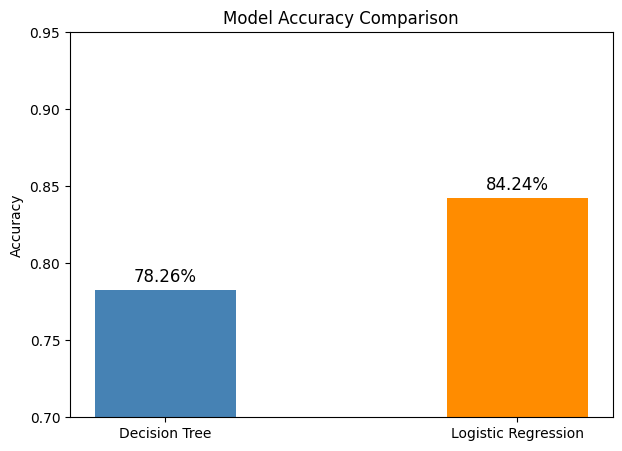

In [49]:
models = ['Decision Tree', 'Logistic Regression']
accuracies = [dt_accuracy, lr_accuracy]

plt.figure(figsize=(7, 5))
bars = plt.bar(models, accuracies, color=['steelblue', 'darkorange'], width=0.4)
plt.ylim(0.7, 0.95)
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
for bar, acc in zip(bars, accuracies):
   plt.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{acc:.2%}', ha='center', fontsize=12)
plt.show()


### 6. Performance Summary

| Model               | Precision | Recall | F1-Score | Accuracy |
|---------------------|-----------|--------|----------|----------|
| Decision Tree       | 0.79      | 0.78   | 0.78     | 78%      |
| Logistic Regression | 0.85      | 0.84   | 0.84     | 84%      |

Logistic Regression outperformed Decision Tree across all metrics.

---

### 2. Confusion Matrix Analysis

**Decision Tree:**
- Correctly predicted 80 patients with heart disease (True Positives)
- Correctly predicted 64 healthy patients (True Negatives)
- Missed 27 actual disease cases — predicted healthy but they were sick (False Negatives)
- Wrongly flagged 13 healthy patients as diseased (False Positives)

**Logistic Regression:**
- Correctly predicted 87 patients with heart disease (True Positives)
- Correctly predicted 68 healthy patients (True Negatives)
- Missed only 20 actual disease cases (False Negatives)
- Wrongly flagged only 9 healthy patients as diseased (False Positives)

---

### 3. Recall — The Most Critical Metric Here

In heart disease prediction, missing a sick patient (False Negative) 
is far more dangerous than a false alarm.

- Decision Tree Recall (Disease):        0.75  → missed 27 sick patients
- Logistic Regression Recall (Disease):  0.81  → missed only 20 sick patients

Logistic Regression is the safer model in a medical context.

---

### 4. Why Logistic Regression Performed Better

- The relationship between clinical features and heart disease 
  is approximately linear, which fits Logistic Regression's assumptions.
- Decision Tree overfitted the training data — it learned the training 
  patterns too closely and failed to generalize well to unseen data,
  which explains its lower recall and f1-score.

---

### 5. Conclusion

- Logistic Regression is the recommended model
  achieving 84% accuracy and an F1-score of 0.86 for disease detection.
- It produced fewer missed diagnoses (20 vs 27), making it more 
  reliable for real-world clinical use.
- Future improvements could include applying Random Forest or XGBoost,
  and using cross-validation for more robust evaluation.
